In [2]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print(sys.executable)
print("pandas:", pd.__version__)

c:\Users\AHMED\Desktop\Calories Burned Prediction\.venv\Scripts\python.exe
pandas: 3.1.0


In [3]:
calories = pd.read_csv("../data/calories.csv")
exercise = pd.read_csv("../data/exercise.csv")

print("calories:", calories.shape)
print("exercise:", exercise.shape)

df = exercise.merge(calories, on="User_ID", how="inner")
print("merged:", df.shape)

df.head()

calories: (15000, 2)
exercise: (15000, 8)
merged: (15000, 9)


,User_ID,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,Calories
0,14733363,male,68,190.0,94.0,29.0,105.0,40.8,231.0
1,14861698,female,20,166.0,60.0,14.0,94.0,40.3,66.0
2,11179863,male,69,179.0,79.0,5.0,88.0,38.7,26.0
3,16180408,female,34,179.0,71.0,13.0,100.0,40.5,71.0
4,17771927,female,27,154.0,58.0,10.0,81.0,39.8,35.0


In [4]:
df.info()

print("\nMissing values per column:")
print(df.isnull().sum())

print("\nDuplicated rows:", df.duplicated().sum())
print("Duplicated User_ID:", df["User_ID"].duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   User_ID     15000 non-null  int64  
 1   Gender      15000 non-null  str    
 2   Age         15000 non-null  int64  
 3   Height      15000 non-null  float64
 4   Weight      15000 non-null  float64
 5   Duration    15000 non-null  float64
 6   Heart_Rate  15000 non-null  float64
 7   Body_Temp   15000 non-null  float64
 8   Calories    15000 non-null  float64
dtypes: float64(6), int64(2), str(1)
memory usage: 1.0 MB

Missing values per column:
User_ID       0
Gender        0
Age           0
Height        0
Weight        0
Duration      0
Heart_Rate    0
Body_Temp     0
Calories      0
dtype: int64

Duplicated rows: 0
Duplicated User_ID: 0


In [5]:
df.describe().round(2)

,User_ID,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,Calories
count,15000.00,15000.00,15000.00,15000.00,15000.00,15000.00,15000.00,15000.00
mean,14977358.54,42.79,174.47,74.97,15.53,95.52,40.03,89.54
std,2872851.45,16.98,14.26,15.04,8.32,9.58,0.78,62.46
min,10001159.00,20.00,123.00,36.00,1.00,67.00,37.10,1.00
25%,12474190.75,28.00,164.00,63.00,8.00,88.00,39.60,35.00
50%,14997285.00,39.00,175.00,74.00,16.00,96.00,40.20,79.00
75%,17449278.75,56.00,185.00,87.00,23.00,103.00,40.60,138.00
max,19999647.00,79.00,222.00,132.00,30.00,128.00,41.50,314.00


In [6]:
df_clean = df.copy()

# 1) drop the identifier (no predictive value)
df_clean = df_clean.drop(columns=["User_ID"])

# 2) convert Gender from text to numbers
df_clean["Gender"] = df_clean["Gender"].str.strip().str.lower().map({"male": 1, "female": 0})

print(df_clean["Gender"].value_counts())
print("Missing after mapping:", df_clean["Gender"].isnull().sum())

df_clean.head()

Gender
0    7553
1    7447
Name: count, dtype: int64
Missing after mapping: 0


,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,Calories
0,1,68,190.0,94.0,29.0,105.0,40.8,231.0
1,0,20,166.0,60.0,14.0,94.0,40.3,66.0
2,1,69,179.0,79.0,5.0,88.0,38.7,26.0
3,0,34,179.0,71.0,13.0,100.0,40.5,71.0
4,0,27,154.0,58.0,10.0,81.0,39.8,35.0


NameError: name 'num_cols' is not defined

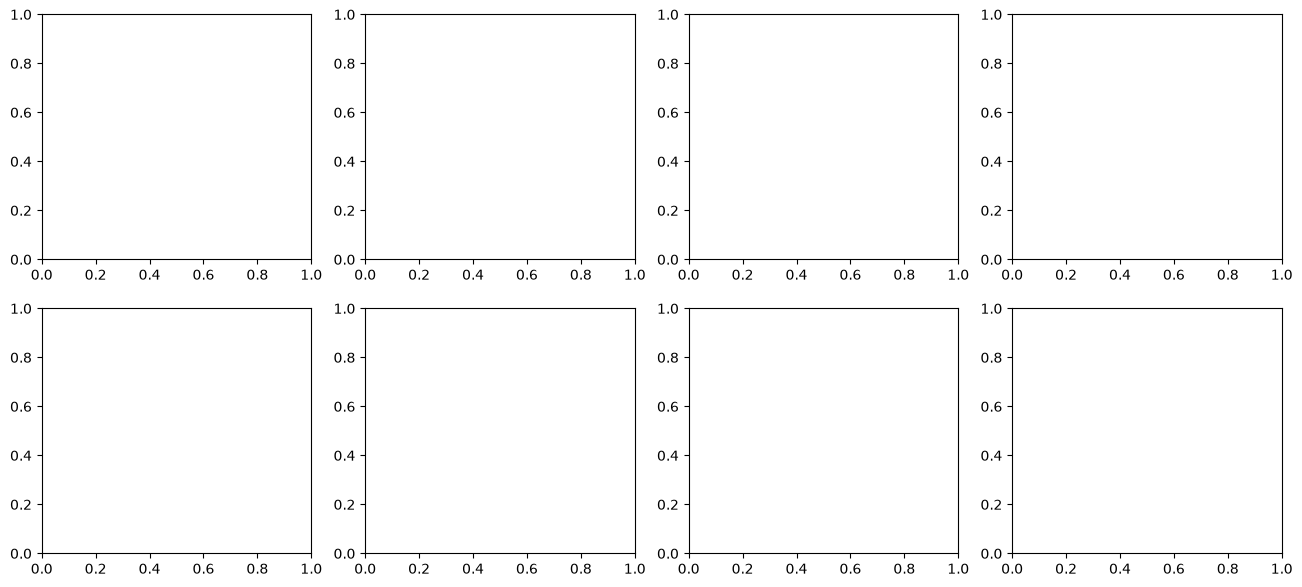

In [7]:
import os
os.makedirs("../figures", exist_ok=True)

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df_clean[col], kde=True, ax=ax)
    ax.set_title(col)
axes.ravel()[-1].set_visible(False)   # 7 columns, 8 slots

plt.tight_layout()
plt.savefig("../figures/distributions.png", dpi=130)
plt.show()

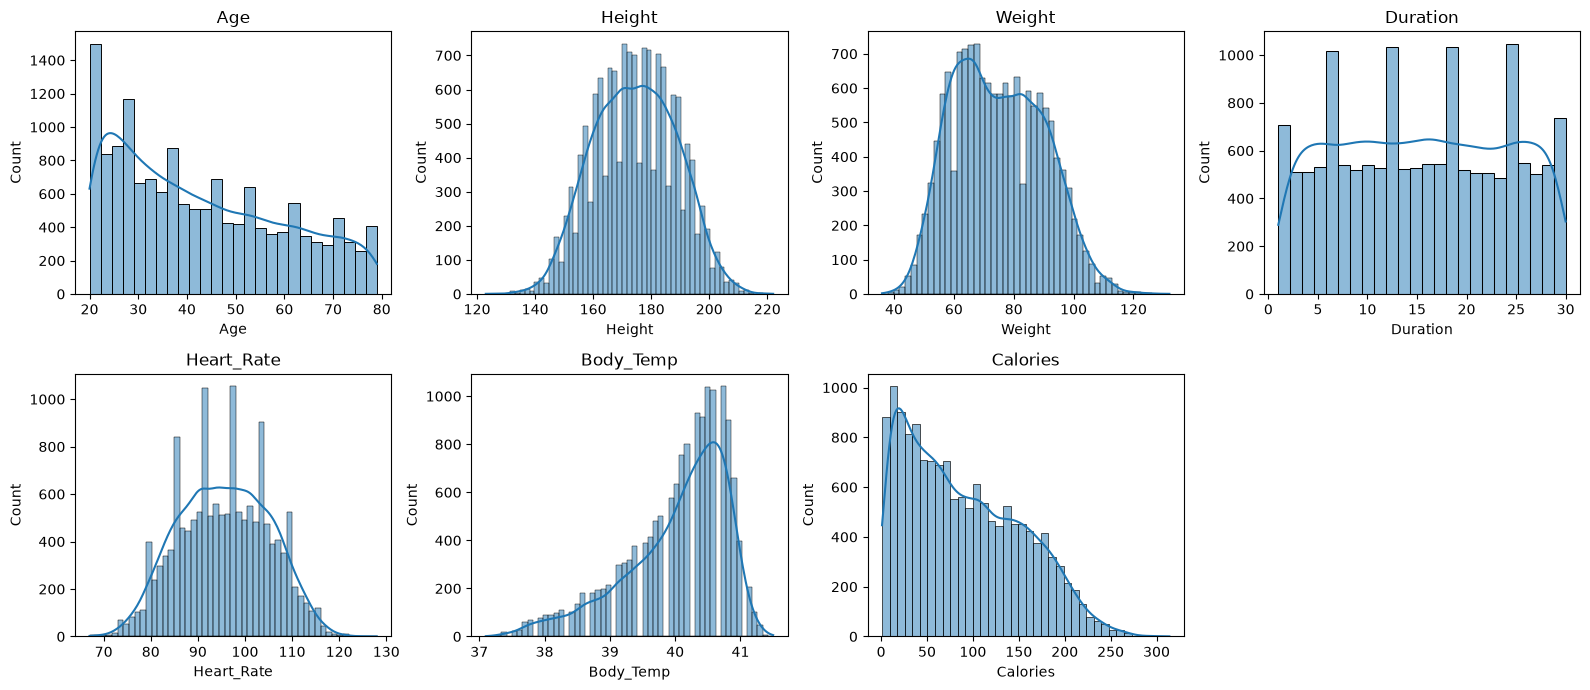

In [8]:
import os
os.makedirs("../figures", exist_ok=True)

num_cols = ["Age", "Height", "Weight", "Duration", "Heart_Rate", "Body_Temp", "Calories"]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df_clean[col], kde=True, ax=ax)
    ax.set_title(col)
axes.ravel()[-1].set_visible(False)   # 7 columns, 8 slots

plt.tight_layout()
plt.savefig("../figures/distributions.png", dpi=130)
plt.show()

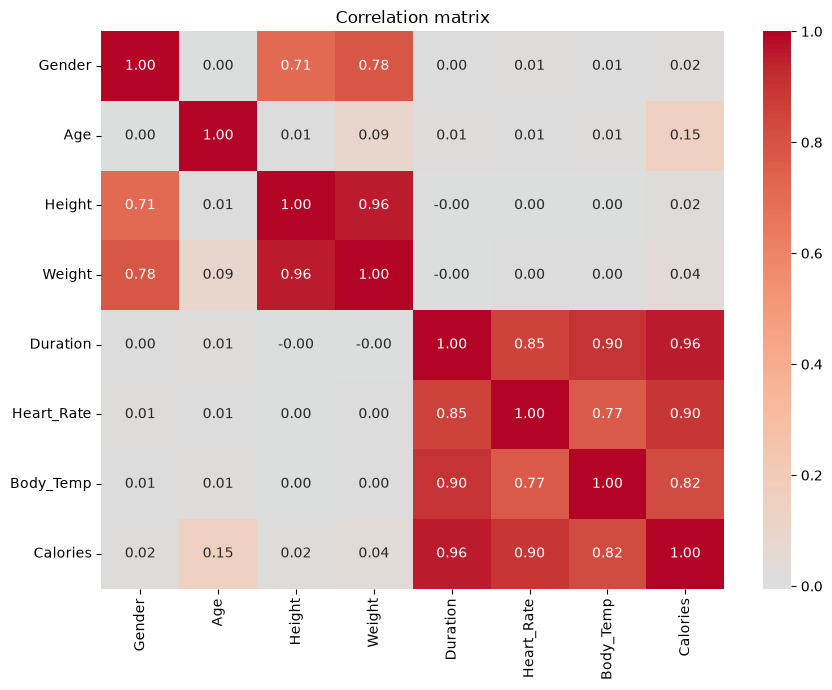

In [9]:
plt.figure(figsize=(9, 7))
sns.heatmap(df_clean.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.tight_layout()
plt.savefig("../figures/correlation.png", dpi=130)
plt.show()

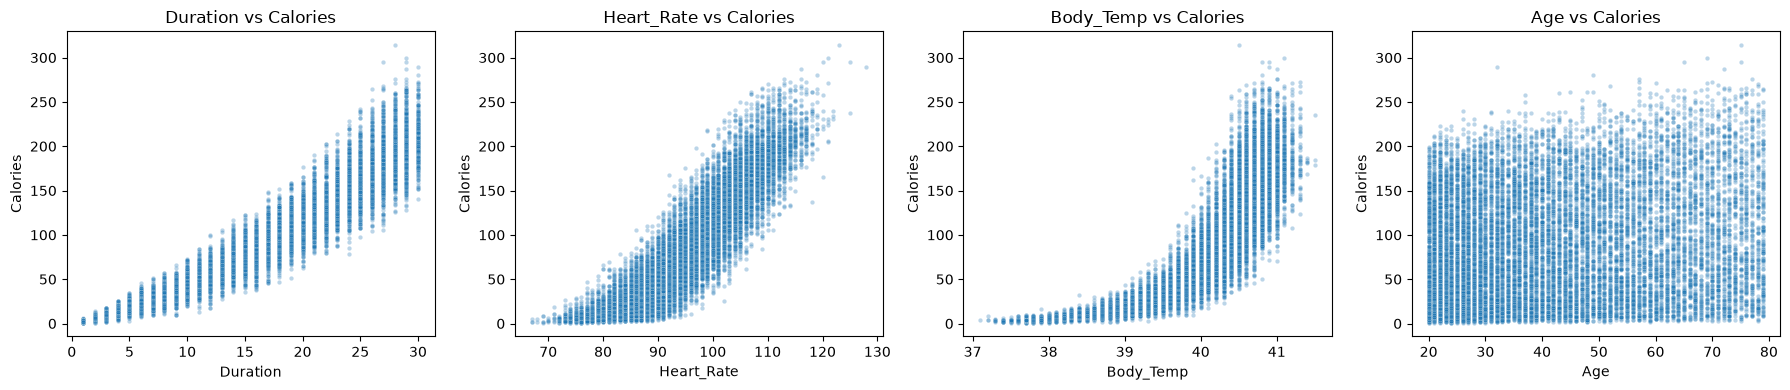

In [10]:
features = ["Duration", "Heart_Rate", "Body_Temp", "Age"]

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, features):
    sns.scatterplot(data=df_clean, x=col, y="Calories", alpha=0.3, s=10, ax=ax)
    ax.set_title(f"{col} vs Calories")

plt.tight_layout()
plt.savefig("../figures/features_vs_calories.png", dpi=130)
plt.show()